<a href="https://colab.research.google.com/github/swarnapatro/AI_KickStart/blob/main/Deep_Learning_Fundamentals_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 Gen AI and Agentic AI Certification Course
## Module: Deep Learning Fundamentals
### From **one neuron** to **how ChatGPT picks its next word**

---

**Instructions for students:**
- Run each cell in order (Shift + Enter).
- Read the explanation in each text cell **before** running the code below it.
- Wherever you see **🔧 Your Turn**, change a value and re-run to see what happens.
- Try the **Practice Exercises** at the end on your own.

**What you will actually build in this notebook:**
1. A **neuron from scratch** in NumPy — and prove it *is* logistic regression.
2. Watch **logistic regression FAIL** on a problem a hidden layer solves in seconds.
3. Write a **full backpropagation loop by hand** and watch the loss fall.
4. Rebuild the same thing in **Keras in 10 lines**.
5. **Overfit** a network on purpose, then **fix it** with dropout + early stopping.
6. See **softmax** — the exact mechanism an LLM uses to choose a word.

> 💡 No GPU needed. Everything here runs on a free Colab CPU in a couple of minutes.


## 1️⃣ Step 1: Setup

We use **NumPy** to build networks from scratch (so nothing is hidden), then **Keras** (inside
TensorFlow) to do the same thing the professional way.

Colab already has TensorFlow installed, so there is nothing to install.


In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # quieten TensorFlow's startup logs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

print("✅ Setup complete")
print("TensorFlow version:", tf.__version__)


✅ Setup complete
TensorFlow version: 2.20.0


## 2️⃣ Step 2: A Neuron IS Logistic Regression

Remember? Logistic regression computed:

$$ p = \text{sigmoid}(b_0 + b_1x_1 + b_2x_2 + \dots) $$

A **neuron** computes:

$$ a = \text{activation}(w \cdot x + b) $$

**These are the same equation.** The regression *coefficients* are now called **weights**; the
*intercept* is now called the **bias**; the *sigmoid* is one choice of **activation**.

Let's build one neuron in 3 lines and prove it.


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def neuron(x, w, b, activation=sigmoid):
    z = np.dot(x, w) + b     # 1. weighted sum  (the "regression" part)
    return activation(z)     # 2. squash it     (the "logistic" part)

#def neuron(x, w, b):
#    z = np.dot(x, w) + b     # 1. weighted sum  (the "regression" part)
#    return 1 / (1 + np.exp(-z))     # 2. squash it     (the "logistic" part)

# One patient: [glucose_scaled, bmi_scaled]
x = np.array([1.2, 0.8])
w = np.array([2.0, 1.5])   # weights  = how much each input matters
b = -1.0                   # bias     = the baseline offset

output = neuron(x, w, b)

print(f"Inputs   x = {x}")
print(f"Weights  w = {w}")
print(f"Bias     b = {b}")
print(f"\nWeighted sum z = (1.2 x 2.0) + (0.8 x 1.5) + (-1.0) = {np.dot(x, w) + b:.2f}")
print(f"Output    a = sigmoid(z) = {output:.4f}")
print("\n👉 That number is a PROBABILITY. This single neuron is a logistic regression classifier.")


Inputs   x = [1.2 0.8]
Weights  w = [2.  1.5]
Bias     b = -1.0

Weighted sum z = (1.2 x 2.0) + (0.8 x 1.5) + (-1.0) = 2.60
Output    a = sigmoid(z) = 0.9309

👉 That number is a PROBABILITY. This single neuron is a logistic regression classifier.


### 🔬 Proof: our neuron reproduces scikit-learn's LogisticRegression exactly

If a neuron really *is* logistic regression, then copying sklearn's learned coefficients into our
neuron should give **identical** predictions. Let's check.


In [ ]:
# Train a real logistic regression on some toy data
X_toy = np.random.randn(200, 2)
y_toy = (X_toy[:, 0] + X_toy[:, 1] > 0).astype(int)

lr = LogisticRegression().fit(X_toy, y_toy)

# Pull out its learned coefficients and intercept
w_learned = lr.coef_[0]      # the WEIGHTS
b_learned = lr.intercept_[0] # the BIAS

# Feed them into OUR hand-built neuron
test_point = np.array([0.7, -0.3])

sklearn_prob = lr.predict_proba([test_point])[0][1]
our_prob     = neuron(test_point, w_learned, b_learned)

print(f"sklearn's LogisticRegression says : {sklearn_prob:.6f}")
print(f"our 3-line neuron says           : {our_prob:.6f}")
print(f"\nDifference: {abs(sklearn_prob - our_prob):.10f}")
print("\n✅ IDENTICAL. A neuron is logistic regression. You already knew deep learning's atom.")


sklearn's LogisticRegression says : 0.826123
our 3-line neuron says           : 0.826123

Difference: 0.0000000000

✅ IDENTICAL. A neuron is logistic regression. You already knew deep learning's atom.


In [ ]:
y_toy

array([1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1,
       0, 1])

## 3️⃣ Step 3: Activation Functions — the Non-Linearity

The activation is what makes a network **non-linear**. Without it, stacking 100 layers would collapse
into a single straight line — all that depth would buy you *nothing*.

| Activation | Where you use it |
|---|---|
| **ReLU** — `max(0, z)` | **hidden layers** (the default) |
| **Sigmoid** — squashes to 0–1 | **output** layer for binary classification |
| **Softmax** — probabilities summing to 1 | **output** layer for multi-class *(this is the LLM one!)* |
| **Tanh** — squashes to −1 to 1 | sometimes in RNNs |


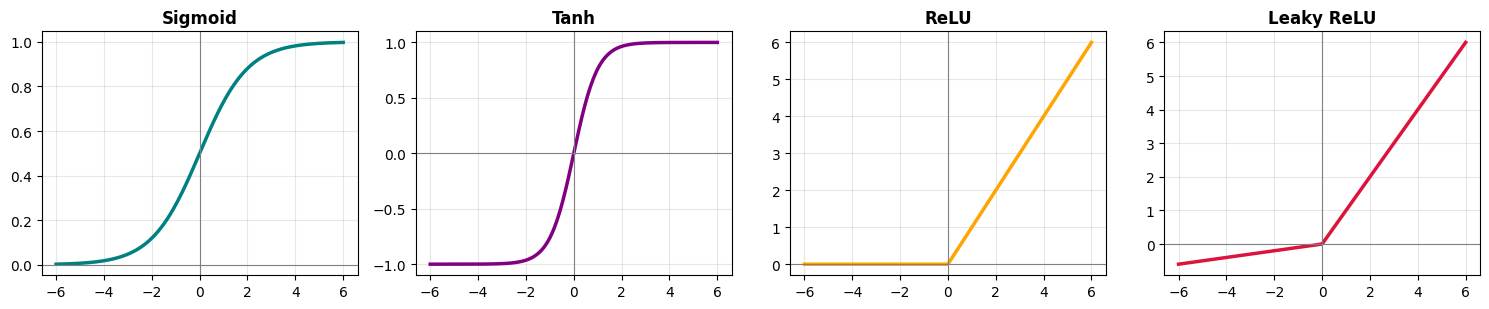

👉 Notice ReLU is just 'if negative, output 0'. That absurdly simple function
   is what made training DEEP networks possible.


In [ ]:
def relu(z):     return np.maximum(0, z)
def tanh(z):     return np.tanh(z)
def leaky_relu(z): return np.where(z > 0, z, 0.1 * z)

z = np.linspace(-6, 6, 200)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (name, fn, colour) in zip(axes, [
        ("Sigmoid", sigmoid, "teal"), ("Tanh", tanh, "purple"),
        ("ReLU", relu, "orange"), ("Leaky ReLU", leaky_relu, "crimson")]):
    ax.plot(z, fn(z), color=colour, linewidth=2.5)
    ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
    ax.set_title(name, fontweight='bold'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("👉 Notice ReLU is just 'if negative, output 0'. That absurdly simple function")
print("   is what made training DEEP networks possible.")


### Softmax — the function an LLM uses to pick its next word

**This is the most important activation for GenAI.** It takes a list of raw scores (called
**logits**) and turns them into **probabilities that sum to 1**.

An LLM produces one logit per word in its vocabulary (~100,000 of them), softmaxes them, and samples
a word from the resulting distribution. Let's do it in miniature.


In [ ]:
def softmax(logits):
    e = np.exp(logits - np.max(logits))   # subtract max for numerical stability
    return e / e.sum()

# Pretend our LLM has a 5-word vocabulary and is completing: "The cat sat on the ___"
vocab  = ["mat", "floor", "roof", "banana", "quickly"]
logits = np.array([3.2, 1.8, 0.9, -1.2, -0.5])   # raw scores from the final layer

probs = softmax(logits)

print("Completing: 'The cat sat on the ___'\n")
print(f"{'word':>10} | {'logit':>6} | {'probability':>11}")
print("-" * 34)
for w, l, p in zip(vocab, logits, probs):
    #bar = "█" * int(p * 40)
    print(f"{w:>10} | {l:>6.1f} | {p:>2.2}")

print(f"\nProbabilities sum to: {probs.sum():.4f}  ✅ (that's what softmax guarantees)")
print(f"\n👉 The model would most likely pick '{vocab[np.argmax(probs)]}'.")
print("   THIS IS HOW AN LLM CHOOSES A WORD. It is logistic regression with 100,000 classes.")


Completing: 'The cat sat on the ___'

      word |  logit | probability
----------------------------------
       mat |    3.2 | 0.72
     floor |    1.8 | 0.18
      roof |    0.9 | 0.072
    banana |   -1.2 | 0.0089
   quickly |   -0.5 | 0.018

Probabilities sum to: 1.0000  ✅ (that's what softmax guarantees)

👉 The model would most likely pick 'mat'.
   THIS IS HOW AN LLM CHOOSES A WORD. It is logistic regression with 100,000 classes.


### 🔧 Your Turn: what does *temperature* actually do?

You have heard "turn up the temperature for more creativity." Now you can see **exactly** what it
does: it divides the logits before the softmax, **reshaping the probability distribution**.

Run this, then change the temperatures in the list.


In [ ]:
for temperature in [0.2, 1.0, 5.0]:      # 🔧 try 0.1 and 5.0 too, default temparature is 1
    probs_t = softmax(logits / temperature)
    top = vocab[np.argmax(probs_t)]
    dist = "  ".join(f"{w}:{p:.0%}" for w, p in zip(vocab, probs_t))
    print(f"temperature={temperature:<4} -> {dist}")

print("\n👉 LOW temperature  = sharp distribution -> almost always picks 'mat' (focused, repetitive)")
print("👉 HIGH temperature = flat distribution  -> may pick 'banana' (creative... or nonsense)")
print("\n   'Temperature' is not magic — it is just dividing the logits before softmax.")


temperature=0.2  -> mat:100%  floor:0%  roof:0%  banana:0%  quickly:0%
temperature=1.0  -> mat:72%  floor:18%  roof:7%  banana:1%  quickly:2%
temperature=5.0  -> mat:30%  floor:23%  roof:19%  banana:13%  quickly:15%

👉 LOW temperature  = sharp distribution -> almost always picks 'mat' (focused, repetitive)
👉 HIGH temperature = flat distribution  -> may pick 'banana' (creative... or nonsense)

   'Temperature' is not magic — it is just dividing the logits before softmax.


## 4️⃣ Step 4: Why We Need Hidden Layers — the XOR Problem ⭐

**This is the single most important experiment in this notebook.**

**XOR** = output `1` when the two inputs **differ**:

| x1 | x2 | y |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | **1** |
| 1 | 0 | **1** |
| 1 | 1 | 0 |

Plot those 4 points. The two `1`s are on opposite corners, and so are the two `0`s. **No straight
line can separate them.**

Logistic regression can *only* draw a straight line. So what happens?


LOGISTIC REGRESSION on XOR:
  predictions : [0 0 0 0]
  truth       : [0 1 1 0]
  ACCURACY    : 50%   <-- 😱 a coin flip!



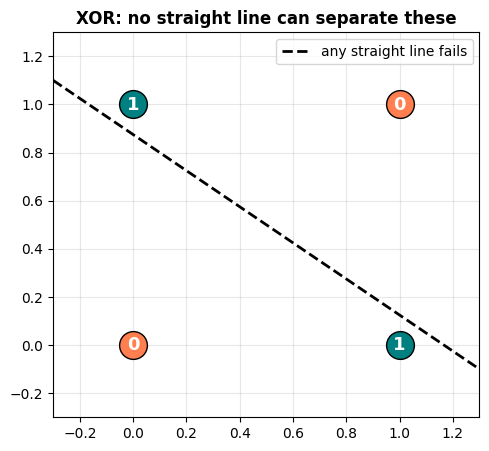

👉 A single neuron CANNOT solve XOR. This limitation nearly killed neural
   networks in the 1970s. The fix: add a HIDDEN LAYER.


In [ ]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

# Try logistic regression (a single neuron) on XOR
lr_xor = LogisticRegression().fit(X_xor, y_xor)
preds = lr_xor.predict(X_xor)

print("LOGISTIC REGRESSION on XOR:")
print(f"  predictions : {preds}")
print(f"  truth       : {y_xor}")
print(f"  ACCURACY    : {lr_xor.score(X_xor, y_xor):.0%}   <-- 😱 a coin flip!\n")

# Visualise why
plt.figure(figsize=(5.5, 5))
for (x1, x2), label in zip(X_xor, y_xor):
    plt.scatter(x1, x2, s=400, c=('teal' if label == 1 else 'coral'),
                edgecolors='black', zorder=3)
    plt.text(x1, x2, str(label), ha='center', va='center',
             color='white', fontweight='bold', fontsize=13, zorder=4)
plt.plot([-0.3, 1.3], [1.1, -0.1], 'k--', lw=2, label='any straight line fails')
plt.xlim(-0.3, 1.3); plt.ylim(-0.3, 1.3)
plt.title('XOR: no straight line can separate these', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("👉 A single neuron CANNOT solve XOR. This limitation nearly killed neural")
print("   networks in the 1970s. The fix: add a HIDDEN LAYER.")


## 5️⃣ Step 5: Build a Network + Backpropagation **From Scratch** ⭐

Now we add **one hidden layer** with 4 neurons — and we write the **entire training loop by hand**,
so nothing is hidden from you.

The loop is exactly the 4 steps from the slides:

1. **Forward pass** — compute the prediction
2. **Loss** — how wrong are we? *(binary cross-entropy)*
3. **Backward pass** — backprop: each weight's share of the blame *(the chain rule)*
4. **Update** — `weight = weight - learning_rate x gradient`

That's it. That is all of deep learning.


In [ ]:
np.random.seed(42)

# --- Architecture: 2 inputs -> 4 hidden (sigmoid) -> 1 output (sigmoid) ---
W1 = np.random.randn(2, 4)      # weights: input -> hidden
b1 = np.zeros((1, 4))           # biases for the hidden layer
W2 = np.random.randn(4, 1)      # weights: hidden -> output
b2 = np.zeros((1, 1))
y_col = y_xor.reshape(-1, 1)
W1

array([[ 0.49671415, -0.1382643 ,  0.64768854,  1.52302986],
       [-0.23415337, -0.23413696,  1.57921282,  0.76743473]])

In [ ]:
np.random.seed(42)

# --- Architecture: 2 inputs -> 4 hidden (sigmoid) -> 1 output (sigmoid) ---
W1 = np.random.randn(2, 4)      # weights: input -> hidden
b1 = np.zeros((1, 4))           # biases for the hidden layer
W2 = np.random.randn(4, 1)      # weights: hidden -> output
b2 = np.zeros((1, 1))           # bias for the output

y_col = y_xor.reshape(-1, 1)    # make y a column vector
lr = 0.5                        # learning rate
losses = []

for epoch in range(5000):

    # ---- 1. FORWARD PASS ----
    z1 = X_xor @ W1 + b1        # weighted sum, hidden layer
    a1 = sigmoid(z1)            # activation
    z2 = a1 @ W2 + b2           # weighted sum, output layer
    out = sigmoid(z2)           # prediction (a probability)

    # ---- 2. LOSS (binary cross-entropy) ----
    loss = -np.mean(y_col * np.log(out + 1e-9) + (1 - y_col) * np.log(1 - out + 1e-9))
    losses.append(loss)

    # ---- 3. BACKWARD PASS (backpropagation = the chain rule) ----
    d_out = (out - y_col) / len(X_xor)      # error at the output
    dW2 = a1.T @ d_out                      # blame for W2
    db2 = d_out.sum(axis=0, keepdims=True)

    d_hidden = (d_out @ W2.T) * a1 * (1 - a1)   # push error BACK through the hidden layer
    dW1 = X_xor.T @ d_hidden                    # blame for W1
    db1 = d_hidden.sum(axis=0, keepdims=True)

    # ---- 4. UPDATE (gradient descent) ----
    W2 -= lr * dW2;  b2 -= lr * db2
    W1 -= lr * dW1;  b1 -= lr * db1

print(f"Loss at epoch    0 : {losses[0]:.4f}")
print(f"Loss at epoch 5000 : {losses[-1]:.4f}\n")
print(f"Predictions : {np.round(out.ravel(), 3)}")
print(f"Truth       : {y_xor}")
print(f"\n✅ SOLVED! Accuracy: {((out.ravel() > 0.5).astype(int) == y_xor).mean():.0%}")
print("\n👉 Logistic regression got 50%. One hidden layer gets 100%.")
print("   The hidden neurons INVENTED new features that made XOR separable.")


Loss at epoch    0 : 0.7628
Loss at epoch 5000 : 0.0028

Predictions : [0.001 0.998 0.996 0.004]
Truth       : [0 1 1 0]

✅ SOLVED! Accuracy: 100%

👉 Logistic regression got 50%. One hidden layer gets 100%.
   The hidden neurons INVENTED new features that made XOR separable.


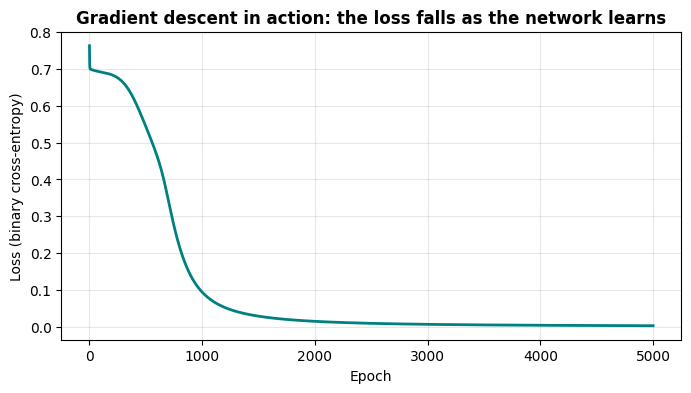

👉 THAT CURVE is gradient descent. Every neural network ever trained — including
   GPT — produces a curve like this. You just implemented it in ~15 lines.


In [ ]:
1plt.figure(figsize=(8, 4))
plt.plot(losses, color='teal', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Loss (binary cross-entropy)')
plt.title('Gradient descent in action: the loss falls as the network learns', fontweight='bold')
plt.grid(alpha=0.3); plt.show()

print("👉 THAT CURVE is gradient descent. Every neural network ever trained — including")
print("   GPT — produces a curve like this. You just implemented it in ~15 lines.")


## 6️⃣ Step 6: The Same Thing in Keras (10 lines)

You have now written a neural network by hand. Here is the professional version — and **nothing new
is happening**. `model.fit()` runs the exact same 4 steps you just coded.


In [ ]:
model = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(4, activation='sigmoid'),   # hidden layer (4 neurons)
    keras.layers.Dense(1, activation='sigmoid'),   # output layer (1 probability)
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()          # <-- look at the parameter count BEFORE training

model.fit(X_xor, y_xor, epochs=500, verbose=1)      # <- the 4 steps, 500 times
#model.summary()
print("\nKeras predictions:", np.round(model.predict(X_xor, verbose=0).ravel(), 3))
print("Truth            :", y_xor)
print(f"\nAccuracy: {model.evaluate(X_xor, y_xor, verbose=0)[1]:.0%}  ✅ same result as our from-scratch version")


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_33 (Dense)                │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.2500 - loss: 0.6965
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.5000 - loss: 0.7051
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5000 - loss: 0.6953
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5000 - loss: 0.6946
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5000 - loss: 0.6979
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5000 - loss: 0.6960
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5000 - loss: 0.6928
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5000 - loss: 0.6924
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5000 - loss: 0.6938
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5000 - loss: 0.6939
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5000 - loss: 0.6924
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5000 - loss

👉 Look at the **parameter count** in `model.summary()` — it says **17**. Let's verify by hand:

- Layer 1: 2 inputs × 4 neurons + 4 biases = **12 parameters**
- Layer 2: 4 inputs × 1 neuron + 1 bias = **5 parameters**
- **Total = 17 parameters** ✅

GPT-3 has **175,000,000,000** of them. Same arithmetic — just a lot more of it.

> 💡 If you call `.summary()` *after* training you'll see a bigger number, because Keras then also
> counts the **optimizer's** internal state (Adam keeps 2 extra values per weight).


## 7️⃣ Step 7: Real Data — and Watching a Network **Overfit**

Let's use the **Pima diabetes dataset** from the Logistic Regression notebook, so we can compare
fairly.

We will deliberately build a network that is **far too big** for 768 rows of data (34,000 parameters!)
and watch it **memorise** the training set.


In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin',
        'BMI','DiabetesPedigreeFunction','Age','Outcome']
df = pd.read_csv(url, names=cols)

# Same cleaning as before: biologically-impossible zeros are really missing values
for c in ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']:
    df[c] = df[c].replace(0, np.nan)
    df[c] = df[c].fillna(df[c].median())

X = df.drop(columns='Outcome').values
y = df['Outcome'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# ⚠️ SCALING IS MANDATORY for neural networks (unlike trees!)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("✅ Data ready.  Train:", X_train.shape, " Test:", X_test.shape)

# BASELINE: plain logistic regression from Day 11
baseline = LogisticRegression(max_iter=1000).fit(X_train, y_train)
baseline_acc = baseline.score(X_test, y_test)
print(f"\n📊 BASELINE — Logistic Regression test accuracy: {baseline_acc:.3f}")
print("   (Let's see if a neural network can beat it...)")


✅ Data ready.  Train: (614, 8)  Test: (154, 8)

📊 BASELINE — Logistic Regression test accuracy: 0.708
   (Let's see if a neural network can beat it...)


In [ ]:
# A DELIBERATELY OVERSIZED network: 3 hidden layers x 128 units, no regularisation
big_model = keras.Sequential([
    keras.layers.Input(shape=(8,)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid'),
])
big_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print(f"Parameters: {big_model.count_params():,}  for only {len(X_train)} training rows!")
print("Training... (this takes ~30 seconds)\n")

history_big = big_model.fit(X_train, y_train, validation_split=0.2,
                            epochs=150, batch_size=16, verbose=1)

train_acc = history_big.history['accuracy'][-1]
val_acc = history_big.history['val_accuracy'][-1]
test_acc_big = big_model.evaluate(X_test, y_test, verbose=0)[1]

print(f"Final TRAINING accuracy   : {train_acc:.3f}   <-- 😱 nearly perfect")
print(f"Final VALIDATION accuracy : {val_acc:.3f}")
print(f"TEST accuracy             : {test_acc_big:.3f}")
print(f"\n👉 The network MEMORISED the training patients. The gap between train and")
print(f"   test ({train_acc - test_acc_big:.3f}) IS the overfitting.")


Parameters: 34,305  for only 614 training rows!
Training... (this takes ~30 seconds)

Epoch 1/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.6823 - loss: 0.5683 - val_accuracy: 0.7967 - val_loss: 0.4483
Epoch 2/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7821 - loss: 0.4546 - val_accuracy: 0.8049 - val_loss: 0.4244
Epoch 3/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7963 - loss: 0.4282 - val_accuracy: 0.8130 - val_loss: 0.4183
Epoch 4/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8065 - loss: 0.4120 - val_accuracy: 0.8049 - val_loss: 0.4149
Epoch 5/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8086 - loss: 0.3982 - val_accuracy: 0.7886 - val_loss: 0.4181
Epoch 6/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8147 - loss: 0.3858 - val_accuracy: 0.7886 - val_loss: 0.4203
Epoch 7/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8208 - loss: 0.3735 - val_accuracy: 0.7967 - val_loss: 0.4229
Epoch 8/150
31/31 ━━━━━━

### The train/validation curve — the diagnostic you will read every time

This is the single most important plot in practical deep learning. Watch the **validation loss
(teal) turn upward** while the **training loss (coral) keeps falling**. That crossing point is where
the model stops learning and starts *memorising*.


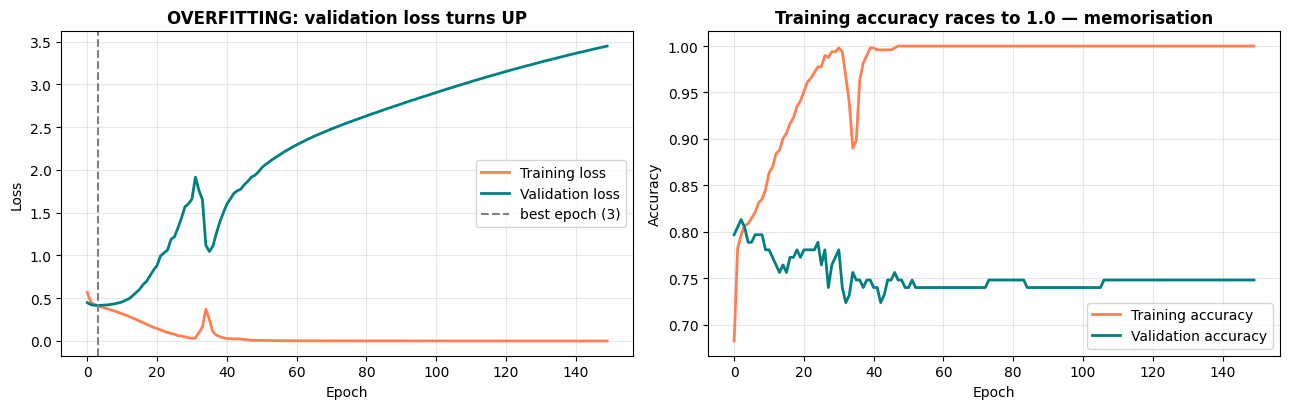

👉 Validation loss was BEST at epoch 3. Every epoch after that made
   the model WORSE in the real world, while looking better on training data.
   That is exactly what Early Stopping automates. Let's use it. 👇


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(history_big.history['loss'], color='coral', lw=2, label='Training loss')
axes[0].plot(history_big.history['val_loss'], color='teal', lw=2, label='Validation loss')
best_epoch = int(np.argmin(history_big.history['val_loss']))
axes[0].axvline(best_epoch, color='grey', ls='--', label=f'best epoch ({best_epoch})')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('OVERFITTING: validation loss turns UP', fontweight='bold')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_big.history['accuracy'], color='coral', lw=2, label='Training accuracy')
axes[1].plot(history_big.history['val_accuracy'], color='teal', lw=2, label='Validation accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training accuracy races to 1.0 — memorisation', fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"👉 Validation loss was BEST at epoch {best_epoch}. Every epoch after that made")
print("   the model WORSE in the real world, while looking better on training data.")
print("   That is exactly what Early Stopping automates. Let's use it. 👇")


## 8️⃣ Step 8: Fixing Overfitting — Dropout + L2 + Early Stopping

Now we apply the defence kit from the slides:

- **Dropout(0.3)** — randomly switch off 30% of neurons each step, so the network can't rely on any
  single unit and must spread its knowledge.
- **L2 regularisation** — penalise large weights (this is *Ridge* like scaler).
- **EarlyStopping** — stop when validation loss stops improving, and **restore the best weights**.

Watch what happens: training accuracy will go **DOWN**, and test accuracy will go **UP**. 🤯


In [ ]:
reg_model = keras.Sequential([
    keras.layers.Input(shape=(8,)),
    keras.layers.Dense(32, activation='relu',
                       kernel_regularizer=keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(16, activation='relu',
                       kernel_regularizer=keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation='sigmoid'),
])
reg_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True)

print(f"Parameters: {reg_model.count_params():,}  (much smaller than {big_model.count_params():,})")
print("Training with dropout + L2 + early stopping...\n")

history_reg = reg_model.fit(X_train, y_train, validation_split=0.2,
                            epochs=200, batch_size=16, verbose=0,
                            callbacks=[early_stop])

train_acc_r = history_reg.history['accuracy'][-1]
test_acc_reg = reg_model.evaluate(X_test, y_test, verbose=0)[1]

print(f"Early stopping halted training at epoch {len(history_reg.history['loss'])} (of 200 allowed)\n")
print(f"{'':<28} | {'Train Acc':>9} | {'Test Acc':>8} | {'Gap':>6}")
print("-" * 60)
print(f"{'Big net (no regularisation)':<28} | {train_acc:>9.3f} | {test_acc_big:>8.3f} | {train_acc-test_acc_big:>6.3f}")
print(f"{'Regularised net':<28} | {train_acc_r:>9.3f} | {test_acc_reg:>8.3f} | {train_acc_r-test_acc_reg:>6.3f}")
print("-" * 60)
print(f"\n👉 The regularised net's TRAINING accuracy dropped from {train_acc:.3f} to {train_acc_r:.3f}")
print("   — it STOPPED MEMORISING. And look at the GAP column: it shrank from")
print(f"   {train_acc-test_acc_big:.3f} to {train_acc_r-test_acc_reg:.3f}. A small gap means the model generalises honestly.")


Parameters: 833  (much smaller than 34,305)
Training with dropout + L2 + early stopping...

Early stopping halted training at epoch 47 (of 200 allowed)

                             | Train Acc | Test Acc |    Gap
------------------------------------------------------------
Big net (no regularisation)  |     1.000 |    0.701 |  0.299
Regularised net              |     0.796 |    0.740 |  0.056
------------------------------------------------------------

👉 The regularised net's TRAINING accuracy dropped from 1.000 to 0.796
   — it STOPPED MEMORISING. And look at the GAP column: it shrank from
   0.299 to 0.056. A small gap means the model generalises honestly.


> ⚠️ **A note on exact numbers.** Neural network training involves randomness (weight initialisation,
> dropout, batch shuffling), so **your numbers will differ slightly from run to run** — that is normal
> and worth knowing. What is *robust* and will reproduce every time:
>
> - The big net's **training accuracy hits 1.000** → it memorised the data.
> - The regularised net has a **much smaller train–test gap** → it generalises honestly.
> - **Neither neural network meaningfully beats logistic regression.** (Keep reading. 👇)


📊 FINAL SCOREBOARD (test accuracy on unseen patients)
Model                                      | Test Acc
--------------------------------------------------------------
Logistic Regression (baseline)             |    0.708
Big neural net, NO regularisation          |    0.721
Neural net + dropout + L2 + early stopping |    0.740

Best neural net beat logistic regression by +3.2 percentage points.
Logistic regression used 9 parameters. The big net used 34,305.


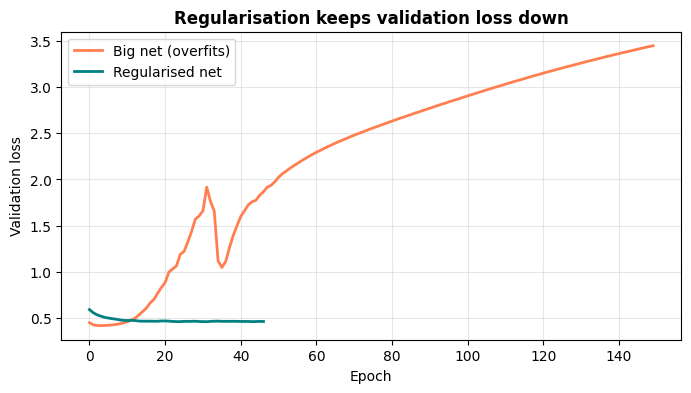

In [ ]:
# The honest scoreboard
print("📊 FINAL SCOREBOARD (test accuracy on unseen patients)")
print("=" * 62)
print(f"{'Model':<42} | {'Test Acc':>8}")
print("-" * 62)
print(f"{'Logistic Regression (baseline)':<42} | {baseline_acc:>8.3f}")
print(f"{'Big neural net, NO regularisation':<42} | {test_acc_big:>8.3f}")
print(f"{'Neural net + dropout + L2 + early stopping':<42} | {test_acc_reg:>8.3f}")
print("=" * 62)

best_nn = max(test_acc_big, test_acc_reg)
gain = (best_nn - baseline_acc) * 100
print(f"\nBest neural net beat logistic regression by {gain:+.1f} percentage points.")
print(f"Logistic regression used 9 parameters. The big net used {big_model.count_params():,}.")

plt.figure(figsize=(8, 4))
plt.plot(history_big.history['val_loss'], color='coral', lw=2, label='Big net (overfits)')
plt.plot(history_reg.history['val_loss'], color='teal', lw=2, label='Regularised net')
plt.xlabel('Epoch'); plt.ylabel('Validation loss')
plt.title('Regularisation keeps validation loss down', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.show()


> 🎯 **The three lessons — and lesson 3 is the professionally valuable one:**
>
> 1. **Regularisation works by making training performance *worse*.** The regularised net scored lower
>    on training data but has a far smaller train–test gap. Trust the *validation* curve, never the
>    training score.
> 2. **Bigger is not better.** 34,000+ parameters for 614 training rows was a licence to memorise.
> 3. **The neural network barely moved the needle over logistic regression** — a 9-parameter model
>    we have seen before. On small tabular data, a neural net is usually **not worth the complexity**. Classical
>    models (especially gradient-boosted trees) typically match or beat it, train in seconds, and stay
>    interpretable.
>
> Deep learning earns its keep on **unstructured** data — text, images, audio — where features cannot
> be hand-crafted and data is plentiful. That is exactly the regime GenAI lives in.
>
> **Being able to say this honestly is what separates an engineer from a hype-follower.**


## 9️⃣ Step 9: Multi-Class + Softmax — the LLM Mechanism, for Real

Now the piece that matters most for GenAI. We classify **handwritten digits (0–9)** — a **10-class**
problem — using a **softmax** output layer.

This is structurally **identical** to what an LLM does. The only difference is the number of classes:

| | Digits | An LLM |
|---|---|---|
| Output units | **10** (one per digit) | **~100,000** (one per vocabulary token) |
| Output activation | **softmax** | **softmax** |
| Loss | **categorical cross-entropy** | **categorical cross-entropy** |

Same machinery. Different scale.


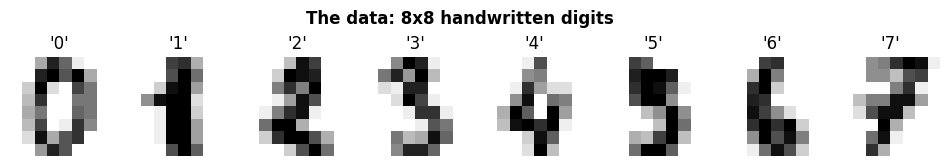

Each image is 8x8 = 64 pixels -> 64 input features
10 possible classes (digits 0-9) -> 10 output units + softmax


In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()
Xd = digits.data / 16.0          # 64 pixels (8x8 image), scaled to 0-1
yd = digits.target               # the digit: 0-9

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.2, random_state=42, stratify=yd)

# Show a few examples
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, lab in zip(axes, digits.images[:8], digits.target[:8]):
    ax.imshow(img, cmap='gray_r'); ax.set_title(f"'{lab}'"); ax.axis('off')
plt.suptitle('The data: 8x8 handwritten digits', fontweight='bold')
plt.show()

print("Each image is 8x8 = 64 pixels -> 64 input features")
print("10 possible classes (digits 0-9) -> 10 output units + softmax")


In [ ]:
digit_model = keras.Sequential([
    keras.layers.Input(shape=(64,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax'),   # <-- 10 classes, softmax!
])

digit_model.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',   # <-- the LLM loss
                    metrics=['accuracy'])

digit_model.fit(Xd_train, yd_train, epochs=30, batch_size=32,
                validation_split=0.1, verbose=0)

test_acc = digit_model.evaluate(Xd_test, yd_test, verbose=0)[1]
print(f"✅ Test accuracy: {test_acc:.3f}")


✅ Test accuracy: 0.969


### Look at the softmax output for a single digit

The network outputs **10 probabilities that sum to 1** — its confidence in each digit. It picks the
highest.

**An LLM does exactly this, but with ~100,000 probabilities — one per word in its vocabulary.**


In [ ]:
i = 7   # 🔧 Your Turn: change this index to inspect a different test digit

probs = digit_model.predict(Xd_test[i:i+1], verbose=0)[0]

print(f"True digit: {yd_test[i]}\n")
print("The network's softmax output (its probability for each class):\n")
for digit, p in enumerate(probs):
    bar = "█" * int(p * 40)
    marker = "  <-- PICKED" if digit == np.argmax(probs) else ""
    print(f"  digit {digit}: {p:>7.2%}  {bar}{marker}")

print(f"\nProbabilities sum to {probs.sum():.4f} ✅")
print(f"\n👉 Prediction: {np.argmax(probs)}   (true answer: {yd_test[i]})")
print("\n🤖 SWAP '10 digits' FOR '100,000 WORDS' AND YOU HAVE AN LLM CHOOSING ITS NEXT TOKEN.")


True digit: 2

The network's softmax output (its probability for each class):

  digit 0:   0.00%  
  digit 1:   0.02%  
  digit 2:  99.20%  ███████████████████████████████████████  <-- PICKED
  digit 3:   0.63%  
  digit 4:   0.00%  
  digit 5:   0.06%  
  digit 6:   0.00%  
  digit 7:   0.01%  
  digit 8:   0.08%  
  digit 9:   0.00%  

Probabilities sum to 1.0000 ✅

👉 Prediction: 2   (true answer: 2)

🤖 SWAP '10 digits' FOR '100,000 WORDS' AND YOU HAVE AN LLM CHOOSING ITS NEXT TOKEN.


## ✅ Summary — What You Actually Built

1. **A neuron from scratch** — and proved it gives *numerically identical* output to sklearn's
   `LogisticRegression`. Deep learning's atom is something you already knew.
2. **Softmax** — and saw that "temperature" is simply dividing the logits before softmaxing. No magic.
3. **The XOR proof** — logistic regression scored **50%** (a coin flip); adding **one hidden layer**
   scored **100%**. Hidden layers *invent new features*, and that is the entire reason depth exists.
4. **Backpropagation by hand** — forward pass → loss → backward pass → update, in ~15 lines of NumPy.
   You watched the loss curve fall. That curve is how *every* network, including GPT, is trained.
5. **The same network in Keras** — `model.fit()` is just those 4 steps, done for you.
6. **Overfitting, live** — a 34,000-parameter net memorised 614 training patients (training accuracy
   → **1.000**) while generalising no better than a 9-parameter logistic regression.
7. **The fix** — dropout + L2 + early stopping shrank the train–test **gap** dramatically: the model
   stopped memorising. (Note: *lower* training accuracy was the sign of success.)
8. **Softmax multi-class** — the exact mechanism an LLM uses to choose its next word.

### 🤖 The bridge to GenAI, in one sentence

> An LLM is a very deep network that takes token **embeddings**, passes them through **attention**
> layers, produces one **logit** per vocabulary word, applies **softmax** to get probabilities, and
> samples the next token — trained with **cross-entropy loss** and **gradient descent**.

**Every bolded word is something you implemented or plotted in this notebook.**

---

## 🧪 Practice Exercises

1. **Break the learning rate.** In the from-scratch XOR loop (Step 5), set `lr = 5.0` and re-run. Then
   try `lr = 0.001`. Plot the loss curve for each. Which one diverges, and which one crawls? Relate
   your answer to the three learning-rate pictures from the slides.

2. **Remove the non-linearity.** In the XOR network, replace `sigmoid` in the *hidden* layer with a
   plain linear function (`def linear(z): return z`). Re-run. Can it still solve XOR? Explain in one
   sentence *why not* — this proves activations are not optional.

3. **Shrink the hidden layer.** Change the hidden layer from 4 neurons to **1** neuron. Does XOR still
   get solved? What is the smallest hidden layer that works?

4. **Fix the overfitting yourself.** Take the `big_model` from Step 7 and, *without* using dropout,
   reduce overfitting only by **making the network smaller**. How few units can you use and still
   match the regularised model's test accuracy?

5. **Prove scaling matters.** Retrain `reg_model` on **unscaled** data (skip the `StandardScaler`).
   What happens to the accuracy and the training time? Why do neural networks need scaling when
   decision trees don't?

6. **Beat the neural net with a tree.** Train a `RandomForestClassifier` on the same diabetes data and
   compare its test accuracy with all three models in the scoreboard. What does this tell you about
   choosing models for tabular data?

7. **Temperature deep-dive (challenge).** Using the `softmax` function from Step 3, write a loop that
   samples 20 words from the 5-word vocabulary at `temperature=0.2` and again at `temperature=2.0`
   (use `np.random.choice(vocab, p=probs)`). Count how often each word appears. Explain how this maps
   to an LLM being "boring" vs "creative".

---
### 🎓 End of Practice Notebook — Gen AI and Agentic AI Certification
